In [4]:
import pandas as pd
from pathlib import Path

# Put kepler_stellar_17.csv.gz in the same folder as this notebook.
FILE = Path("/kaggle/input/datasets/sairakeshnagaram/koi-stellars1/kepler_stellar_17.csv")

df = pd.read_csv(FILE)  # No compression="gzip"

# Confirm that this is the expected Kepler DR25 catalog.
print("Rows:", len(df))
print("Unique Kepler IDs:", df["kepid"].nunique())
print("Catalog versions:")
print(df["st_delivname"].value_counts(dropna=False))

# Check the required columns before filtering.
required = ["kepid", "teff", "dataspan", "dutycycle"]
missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Convert relevant columns to numeric.
for col in ["teff", "dataspan", "dutycycle"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Count stars at each stage so the selection is transparent.
stage_0 = df.drop_duplicates("kepid")
stage_1 = stage_0[
    stage_0["teff"].between(5300, 6000, inclusive="both")
]
stage_2 = stage_1[
    stage_1["dataspan"] >= 730
]
stage_3 = stage_2[
    stage_2["dutycycle"] >= 0.60
]

counts = pd.DataFrame({
    "Selection stage": [
        "All unique DR25 stars",
        "G-star temperature range (5300–6000 K)",
        "At least 730 days of data span",
        "Duty cycle at least 0.60"
    ],
    "Number of stars": [
        len(stage_0),
        len(stage_1),
        len(stage_2),
        len(stage_3)
    ]
})

print("\nPRELIMINARY G-STAR DENOMINATOR")
display(counts)

print("\nTemperature range:", stage_3["teff"].min(),
      "to", stage_3["teff"].max(), "K")
print("Missing duty-cycle values in original catalog:",
      df["dutycycle"].isna().sum())

# Save the preliminary selected target-star list.
stage_3.to_csv("preliminary_G_star_targets.csv", index=False)
print("\nSaved preliminary_G_star_targets.csv")


Rows: 200038
Unique Kepler IDs: 200038
Catalog versions:
st_delivname
q1_q17_dr25_stellar    200038
Name: count, dtype: int64

PRELIMINARY G-STAR DENOMINATOR


,Selection stage,Number of stars
0,All unique DR25 stars,200038
1,G-star temperature range (5300–6000 K),72581
2,At least 730 days of data span,66797
3,Duty cycle at least 0.60,64575



Temperature range: 5300 to 6000 K
Missing duty-cycle values in original catalog: 1336

Saved preliminary_G_star_targets.csv


In [5]:
import pandas as pd
import numpy as np
import requests
from io import StringIO
from urllib.parse import urlencode

# NASA Exoplanet Archive TAP service
TAP_URL = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

query = """
SELECT
    kepid,
    koi_disposition,
    koi_period,
    koi_prad,
    koi_score
FROM q1_q17_dr25_koi
"""

response = requests.get(
    TAP_URL,
    params={"query": query, "format": "csv"},
    timeout=120
)

response.raise_for_status()

koi = pd.read_csv(StringIO(response.text))

print("DR25 KOI rows:", len(koi))
print("Unique KOI host stars:", koi["kepid"].nunique())
print("\nDisposition counts:")
print(koi["koi_disposition"].value_counts(dropna=False))

# Convert relevant columns to numeric
for col in ["kepid", "koi_period", "koi_prad", "koi_score"]:
    koi[col] = pd.to_numeric(koi[col], errors="coerce")

koi["koi_disposition"] = (
    koi["koi_disposition"].astype("string").str.strip().str.upper()
)

display(koi.head())

DR25 KOI rows: 8054
Unique KOI host stars: 6923

Disposition counts:
koi_disposition
FALSE POSITIVE    3965
CONFIRMED         2731
CANDIDATE         1358
Name: count, dtype: int64


,kepid,koi_disposition,koi_period,koi_prad,koi_score
0,10811496,FALSE POSITIVE,19.899140,14.60,0.0
1,10848459,FALSE POSITIVE,1.736952,33.46,0.0
2,10854555,CONFIRMED,2.525592,2.75,1.0
3,10872983,CONFIRMED,11.094321,3.90,1.0
4,10872983,CONFIRMED,4.134435,2.77,1.0


In [6]:
# Use the original DR25 stellar dataframe from Cell 1.
stars = df.copy()

required = ["kepid", "teff", "dataspan", "dutycycle"]
missing = [c for c in required if c not in stars.columns]

if missing:
    raise ValueError(f"Missing stellar columns: {missing}")

for col in required:
    stars[col] = pd.to_numeric(stars[col], errors="coerce")

# One row per target star
stars = stars.drop_duplicates(subset="kepid").copy()

# Apply identical observing-quality criteria
quality = (
    (stars["dataspan"] >= 730) &
    (stars["dutycycle"] >= 0.60)
)

# Temperature definitions used in this project
k_stars = stars[
    quality & stars["teff"].between(3900, 5200)
].copy()

g_stars = stars[
    quality & stars["teff"].between(5300, 6000)
].copy()

print("Matched target-star selection")
print("--------------------------------")
print("K-dwarf targets:", len(k_stars))
print("G-dwarf targets:", len(g_stars))

print("\nK-dwarf temperature range:")
print(k_stars["teff"].min(), "to", k_stars["teff"].max(), "K")

print("\nG-dwarf temperature range:")
print(g_stars["teff"].min(), "to", g_stars["teff"].max(), "K")

# Verify that the two samples do not overlap
overlap = set(k_stars["kepid"]) & set(g_stars["kepid"])
print("\nOverlapping target IDs:", len(overlap))

assert len(overlap) == 0, "K and G samples unexpectedly overlap."

Matched target-star selection
--------------------------------
K-dwarf targets: 34344
G-dwarf targets: 64575

K-dwarf temperature range:
3900 to 5200 K

G-dwarf temperature range:
5300 to 6000 K

Overlapping target IDs: 0


In [7]:
# Keep KOIs in the same illustrative planet domain
planet_domain = koi[
    koi["koi_prad"].between(1, 4) &
    koi["koi_period"].between(1, 100)
].copy()

print("KOI entries in selected planet domain:", len(planet_domain))

print("\nDisposition breakdown:")
print(planet_domain["koi_disposition"].value_counts())

# Join the planet entries to the selected target stars
k_joined = planet_domain.merge(
    k_stars[["kepid", "teff"]],
    on="kepid",
    how="inner"
)

g_joined = planet_domain.merge(
    g_stars[["kepid", "teff"]],
    on="kepid",
    how="inner"
)

print("\nK-dwarf KOI entries:", len(k_joined))
print("G-dwarf KOI entries:", len(g_joined))

KOI entries in selected planet domain: 3442

Disposition breakdown:
koi_disposition
CONFIRMED         2097
CANDIDATE          673
FALSE POSITIVE     672
Name: count, dtype: Int64

K-dwarf KOI entries: 620
G-dwarf KOI entries: 1591


In [8]:
def wilson_interval(successes, total, z=1.96):
    """95% Wilson confidence interval for a binomial proportion."""
    if total == 0:
        return np.nan, np.nan

    p = successes / total
    denominator = 1 + z**2 / total

    center = (p + z**2 / (2 * total)) / denominator

    margin = (
        z * np.sqrt(
            (p * (1 - p) / total) +
            (z**2 / (4 * total**2))
        ) / denominator
    )

    return center - margin, center + margin


def summarize_population(name, target_stars, joined):
    confirmed = joined[
        joined["koi_disposition"] == "CONFIRMED"
    ]

    confirmed_hosts = confirmed["kepid"].dropna().nunique()
    total_targets = target_stars["kepid"].nunique()

    lower, upper = wilson_interval(
        confirmed_hosts,
        total_targets
    )

    return {
        "Population": name,
        "Target stars": total_targets,
        "KOI entries": len(joined),
        "Confirmed KOI entries": int(
            (joined["koi_disposition"] == "CONFIRMED").sum()
        ),
        "Candidate KOI entries": int(
            (joined["koi_disposition"] == "CANDIDATE").sum()
        ),
        "False-positive KOI entries": int(
            (joined["koi_disposition"] == "FALSE POSITIVE").sum()
        ),
        "Unique confirmed host stars": confirmed_hosts,
        "Raw confirmed-host fraction": confirmed_hosts / total_targets,
        "95% CI lower": lower,
        "95% CI upper": upper
    }


results = pd.DataFrame([
    summarize_population("K dwarfs", k_stars, k_joined),
    summarize_population("G dwarfs", g_stars, g_joined)
])

display(results)

results.to_csv("matched_G_K_comparison.csv", index=False)
print("Saved matched_G_K_comparison.csv")

,Population,Target stars,KOI entries,Confirmed KOI entries,Candidate KOI entries,False-positive KOI entries,Unique confirmed host stars,Raw confirmed-host fraction,95% CI lower,95% CI upper
0,K dwarfs,34344,620,459,85,76,318,0.009259,0.008300,0.010329
1,G dwarfs,64575,1591,1011,310,270,751,0.011630,0.010832,0.012486


Saved matched_G_K_comparison.csv


In [9]:
rng = np.random.default_rng(42)
N_BOOTSTRAP = 10000

k_n = int(results.loc[results["Population"] == "K dwarfs",
                      "Target stars"].iloc[0])
g_n = int(results.loc[results["Population"] == "G dwarfs",
                      "Target stars"].iloc[0])

k_hosts = int(results.loc[results["Population"] == "K dwarfs",
                          "Unique confirmed host stars"].iloc[0])
g_hosts = int(results.loc[results["Population"] == "G dwarfs",
                          "Unique confirmed host stars"].iloc[0])

k_fraction = k_hosts / k_n
g_fraction = g_hosts / g_n

observed_difference = g_fraction - k_fraction

# Binomial resampling of the star-level host indicator
k_boot = rng.binomial(k_n, k_fraction, size=N_BOOTSTRAP) / k_n
g_boot = rng.binomial(g_n, g_fraction, size=N_BOOTSTRAP) / g_n

difference_boot = g_boot - k_boot

ci_lower, ci_upper = np.percentile(
    difference_boot, [2.5, 97.5]
)

print("G-dwarf raw confirmed-host fraction:", round(g_fraction, 6))
print("K-dwarf raw confirmed-host fraction:", round(k_fraction, 6))

print("\nG minus K difference:", round(observed_difference, 6))
print("Bootstrap 95% interval:",
      (round(ci_lower, 6), round(ci_upper, 6)))

if ci_lower <= 0 <= ci_upper:
    print("\nInterpretation: The bootstrap interval includes zero.")
else:
    print("\nInterpretation: The bootstrap interval excludes zero.")

G-dwarf raw confirmed-host fraction: 0.01163
K-dwarf raw confirmed-host fraction: 0.009259

G minus K difference: 0.002371
Bootstrap 95% interval: (np.float64(0.0011), np.float64(0.003696))

Interpretation: The bootstrap interval excludes zero.


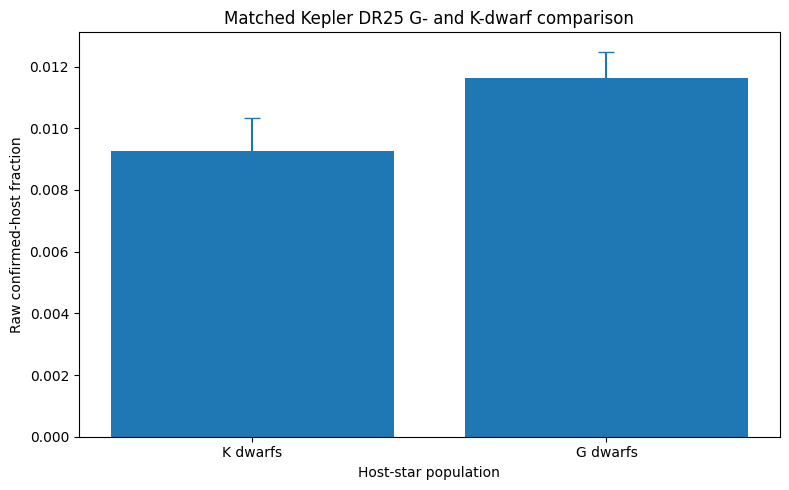

In [10]:
import matplotlib.pyplot as plt

labels = results["Population"].tolist()

fractions = results["Raw confirmed-host fraction"].to_numpy()
lower = results["95% CI lower"].to_numpy()
upper = results["95% CI upper"].to_numpy()

errors = np.vstack([
    fractions - lower,
    upper - fractions
])

plt.figure(figsize=(8, 5))

plt.bar(labels, fractions)
plt.errorbar(
    labels,
    fractions,
    yerr=errors,
    fmt="none",
    capsize=6
)

plt.ylabel("Raw confirmed-host fraction")
plt.xlabel("Host-star population")
plt.title("Matched Kepler DR25 G- and K-dwarf comparison")
plt.tight_layout()
plt.show()

In [11]:
k_joined.to_csv("matched_K_dwarf_KOIs.csv", index=False)
g_joined.to_csv("matched_G_dwarf_KOIs.csv", index=False)

limitations = """
This analysis calculates a raw catalog confirmed-host fraction.

It does not calculate intrinsic planet occurrence rates because it does
not correct for:
1. Planet detection completeness.
2. Geometric transit probability.
3. Candidate reliability and false-positive probabilities beyond the
   catalog disposition classifications.
4. Differences in detectability between stellar populations.

The G- and K-dwarf samples use matched data-span and duty-cycle cuts.
The stellar temperature ranges are project-defined selection criteria.

The results should therefore be interpreted as a descriptive comparison
of confirmed-host fractions in the selected Kepler DR25 catalog, not as
a completeness-corrected occurrence-rate measurement.
"""

with open("matched_G_K_limitations.txt", "w") as f:
    f.write(limitations)

print("Notebook 17 analysis exports completed.")

Notebook 17 analysis exports completed.
